## **Problem 2**

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

In [2]:
df = pd.read_csv("winequality-white.csv", sep=";")

# Load dataset
X = df.drop(columns=["quality"])
y = df["quality"]

# Split: 70% train, 10% validation, 20% test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.125, random_state=42
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 3428
Validation: 490
Test: 980


### Random Forest

In [3]:
rf_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": [0.5, 0.8, 1.0]
}

rf_params = list(ParameterGrid(rf_grid))
print("Number of combinations:", len(rf_params))

Number of combinations: 576


In [4]:
rf_results = []

for params in rf_params:
    model = RandomForestRegressor(
        **params,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    val_pred = model.predict(X_val)
    val_mse = mean_squared_error(y_val, val_pred)

    rf_results.append({
        **params,
        "val_mse": val_mse
    })

rf_results = pd.DataFrame(rf_results)
rf_results = rf_results.sort_values("val_mse")

print(rf_results.head())

     max_depth  max_features  min_samples_leaf  min_samples_split  \
433        NaN           0.5                 1                  2   
434        NaN           0.5                 1                  2   
480        NaN           0.8                 1                  2   
437        NaN           0.5                 1                  5   
528        NaN           1.0                 1                  2   

     n_estimators   val_mse  
433           100  0.308704  
434           200  0.310285  
480            50  0.310978  
437           200  0.313206  
528            50  0.314398  


In [5]:
best_idx = rf_results["val_mse"].idxmin()
best_rf_params = rf_params[best_idx]

best_rf = RandomForestRegressor(
    **best_rf_params,
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_train, y_train)

rf_val_mse = mean_squared_error(
    y_val, best_rf.predict(X_val)
)

rf_test_mse = mean_squared_error(
    y_test, best_rf.predict(X_test)
)

print("Best parameters:", best_rf_params)
print("Validation MSE:", rf_val_mse)
print("Test MSE:", rf_test_mse)


Best parameters: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Validation MSE: 0.3087038775510204
Test MSE: 0.3481839795918368


### KNN

In [6]:
knn_grid = {
    "n_neighbors": list(range(1, 101)),
    "weights": ["uniform", "distance"],
    "p": [1, 2, 3]
}

knn_params = list(ParameterGrid(knn_grid))

print("Number of combinations:", len(knn_params))

Number of combinations: 600


In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [8]:
knn_results = []

for params in knn_params:
    model = KNeighborsRegressor(**params)

    model.fit(X_train_scaled, y_train)
    val_pred = model.predict(X_val_scaled)
    val_mse = mean_squared_error(y_val, val_pred)

    knn_results.append({
        **params,
        "val_mse": val_mse
    })

knn_results = pd.DataFrame(knn_results)
knn_results = knn_results.sort_values("val_mse")

print(knn_results.head())

     n_neighbors  p   weights   val_mse
145           25  1  distance  0.298739
109           19  1  distance  0.299662
103           18  1  distance  0.299994
163           28  1  distance  0.300058
97            17  1  distance  0.300187


In [9]:
best_knn_params = knn_results.iloc[0].drop("val_mse").to_dict()

best_knn = KNeighborsRegressor(**best_knn_params)

best_knn.fit(X_train_scaled, y_train)

knn_val_mse = mean_squared_error(
    y_val, best_knn.predict(X_val_scaled)
)

knn_test_mse = mean_squared_error(
    y_test, best_knn.predict(X_test_scaled)
)

print("Best parameters:", best_knn_params)
print("Validation MSE:", knn_val_mse)
print("Test MSE:", knn_test_mse)

Best parameters: {'n_neighbors': 25, 'p': 1, 'weights': 'distance'}
Validation MSE: 0.2987389892437149
Test MSE: 0.36855023327473463


In [10]:
results = pd.DataFrame({
    "Model": ["Random Forest", "KNN"],
    "Validation MSE": [rf_val_mse, knn_val_mse],
    "Test MSE": [rf_test_mse, knn_test_mse]
})

results["Difference"] = (
    results["Test MSE"] - results["Validation MSE"]
)

print(results.round(4))

           Model  Validation MSE  Test MSE  Difference
0  Random Forest          0.3087    0.3482      0.0395
1            KNN          0.2987    0.3686      0.0698


We randomly split the dataset into 70% training, 10% validation, and 20% test sets. We evaluated 576 hyperparameter configurations for RandomForestRegressor and 600 for KNeighborsRegressor, selecting the best configuration for each model based on validation MSE.

For Random Forest, the validation MSE was 0.3087 and the test MSE was 0.3482. For KNN, the validation MSE was 0.2987 and the test MSE was 0.3686.

For both models, the test MSE was higher than the validation MSE. This suggests that selecting hyperparameters based on validation performance may lead to an optimistic estimate of generalization error. In particular, KNN achieved a lower validation MSE than Random Forest but a higher test MSE, illustrating that better validation performance does not necessarily imply better test performance.

## **Problem 3**

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score


dset0.csv
   Trees  Train Error  Test Error
0      1       0.4250        0.43
1     10       0.1400        0.25
2    100       0.0025        0.19
3    300       0.0000        0.16
4   1000       0.0000        0.18


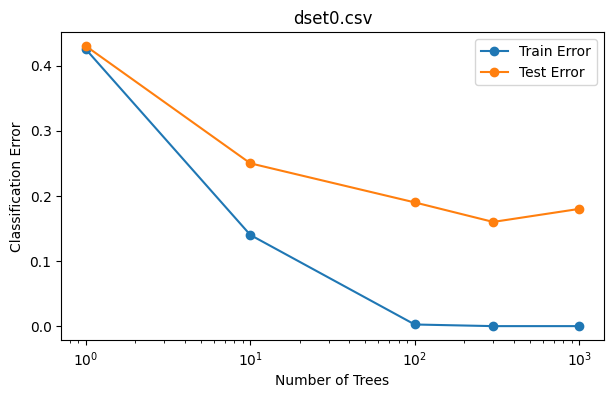


dset1.csv
   Trees  Train Error  Test Error
0      1       0.2950        0.31
1     10       0.1175        0.24
2    100       0.0075        0.19
3    300       0.0000        0.21
4   1000       0.0000        0.21


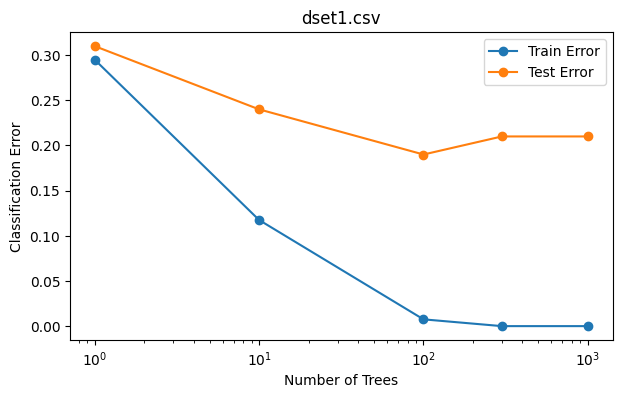

In [13]:
n_trees = [1, 10, 100, 300, 1000]

for filename in ["dset0.csv", "dset1.csv"]:
    df = pd.read_csv(filename, header=None)

    X = df.iloc[:, 1:]
    y = df.iloc[:, 0].astype(int)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    train_error = []
    test_error = []

    for n in n_trees:
        model = GradientBoostingClassifier(
            n_estimators=n,
            random_state=42
        )

        model.fit(X_train, y_train)

        train_error.append(
            1 - accuracy_score(y_train, model.predict(X_train))
        )
        test_error.append(
            1 - accuracy_score(y_test, model.predict(X_test))
        )

    results = pd.DataFrame({
        "Trees": n_trees,
        "Train Error": train_error,
        "Test Error": test_error
    })

    print(f"\n{filename}")
    print(results)

    plt.figure(figsize=(7, 4))
    plt.plot(n_trees, train_error, marker="o", label="Train Error")
    plt.plot(n_trees, test_error, marker="o", label="Test Error")

    plt.xscale("log")
    plt.xlabel("Number of Trees")
    plt.ylabel("Classification Error")
    plt.title(filename)
    plt.legend()
    plt.show()

The difference in generalization behavior may be explained by differences in the noise levels or underlying complexity of the datasets. If dset1 contains more noise than dset0, adding more trees may cause the model to fit noise rather than the underlying signal, leading to earlier overfitting.